1. EXPLORATORY DATA ANALYSIS
2. ПРЕТПРОЦЕСИРАЊЕ НА ПОДАТОЦИТЕ
Вкупно нулти вредности по претпроцесирање: 0
3. ТРЕНИРАЊЕ И ЕВАЛУАЦИЈА НА МОДЕЛ
Тренирање на Random Forest...
  MAE: $134.83, RMSE: $461.26, R²: -0.4629
Тренирање на Linear Regression...
  MAE: $328.57, RMSE: $446.80, R²: -0.3727

СПОРЕДБА НА МОДЕЛИТЕ:
                          MAE            MSE        RMSE        R2
Random Forest      134.828186  212759.743403  461.258868 -0.462940
Linear Regression  328.573223  199632.757568  446.802817 -0.372679


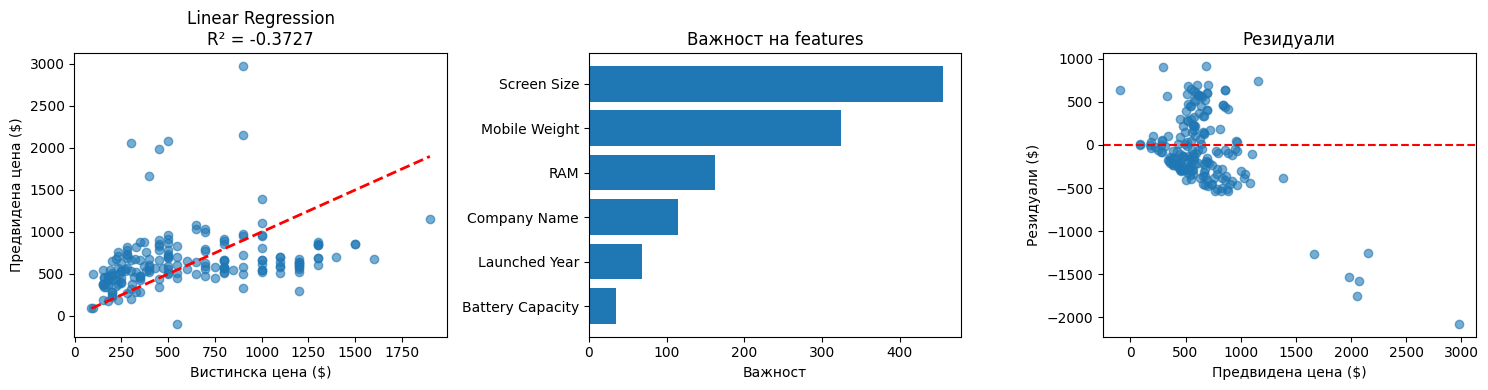


Најдобар модел: Linear Regression
R² score: -0.3727
Просечна грешка: $328.57


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Вчитување на податоците
df = pd.read_csv('phones.csv')

# 1. EDA
print("1. EXPLORATORY DATA ANALYSIS")

# Претпроцесирање на цената
def clean_price(price):
    if pd.isna(price):
        return np.nan
    price_str = str(price)
    price_str = price_str.replace('USD', '').replace(',', '').replace(' ', '').strip()
    try:
        return float(price_str)
    except:
        return np.nan

df['Launched Price (USA)'] = df['Launched Price (USA)'].apply(clean_price)

# Претпроцесирање на другите колони
def clean_numeric(value, unit):
    if pd.isna(value):
        return np.nan
    value_str = str(value)
    value_str = value_str.replace(unit, '').replace(',', '').strip()
    try:
        return float(value_str)
    except:
        return np.nan

df['Battery Capacity'] = df['Battery Capacity'].apply(lambda x: clean_numeric(x, 'mAh'))
df['RAM'] = df['RAM'].apply(lambda x: clean_numeric(x, 'GB'))
df['Screen Size'] = df['Screen Size'].apply(lambda x: clean_numeric(x, 'inches'))
df['Mobile Weight'] = df['Mobile Weight'].apply(lambda x: clean_numeric(x, 'g'))

# 2. ПРЕТПРОЦЕСИРАЊЕ
print("2. ПРЕТПРОЦЕСИРАЊЕ НА ПОДАТОЦИТЕ")

# Отстрани редови каде цената е NaN
df_clean = df.dropna(subset=['Launched Price (USA)']).copy()

# Пополнување на нулти вредности за нумерички колони
numeric_cols = ['Mobile Weight', 'Battery Capacity', 'RAM', 'Screen Size']
for col in numeric_cols:
    df_clean[col].fillna(df_clean[col].median(), inplace=True)

# Пополнување на категориски колони
categorical_cols = ['Company Name', 'Processor']
for col in categorical_cols:
    df_clean[col].fillna(df_clean[col].mode()[0] if not df_clean[col].mode().empty else 'Unknown', inplace=True)

# Кодирање на категориски променливи
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    label_encoders[col] = le

# Провери дали се отстранети сите NaN вредности
print(f"Вкупно нулти вредности по претпроцесирање: {df_clean.isnull().sum().sum()}")

# 3. МОДЕЛИРАЊЕ
print("3. ТРЕНИРАЊЕ И ЕВАЛУАЦИЈА НА МОДЕЛ")

# Подготовка на features и target
features = ['RAM', 'Battery Capacity', 'Screen Size', 'Company Name', 'Launched Year', 'Mobile Weight']
X = df_clean[features]
y = df_clean['Launched Price (USA)']

# Поделба на податоците
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Скалирање
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Тренирање модели
models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Linear Regression': LinearRegression()
}

results = {}
for name, model in models.items():
    print(f"Тренирање на {name}...")
    
    if name == 'Linear Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    # Евалуација
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}
    
    print(f"  MAE: ${mae:.2f}, RMSE: ${rmse:.2f}, R²: {r2:.4f}")

# Прикажи ги резултатите
print("\nСПОРЕДБА НА МОДЕЛИТЕ:")
results_df = pd.DataFrame(results).T
print(results_df)

# Визуелизација
best_model_name = results_df['R2'].idxmax()

plt.figure(figsize=(15, 4))

# Вистински vs Предвидени вредности
plt.subplot(1, 3, 1)
if best_model_name == 'Linear Regression':
    best_model = models['Linear Regression']
    y_pred_best = best_model.predict(X_test_scaled)
else:
    best_model = models['Random Forest']
    y_pred_best = best_model.predict(X_test)

plt.scatter(y_test, y_pred_best, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Вистинска цена ($)')
plt.ylabel('Предвидена цена ($)')
plt.title(f'{best_model_name}\nR² = {results[best_model_name]["R2"]:.4f}')

# Feature importance
plt.subplot(1, 3, 2)
if best_model_name == 'Random Forest':
    importance = best_model.feature_importances_
else:
    importance = np.abs(best_model.coef_)
    
importance_df = pd.DataFrame({'feature': features, 'importance': importance})
importance_df = importance_df.sort_values('importance', ascending=True)
plt.barh(importance_df['feature'], importance_df['importance'])
plt.xlabel('Важност')
plt.title('Важност на features')

# Резидуали
plt.subplot(1, 3, 3)
residuals = y_test - y_pred_best
plt.scatter(y_pred_best, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предвидена цена ($)')
plt.ylabel('Резидуали ($)')
plt.title('Резидуали')

plt.tight_layout()
plt.show()

print(f"\nНајдобар модел: {best_model_name}")
print(f"R² score: {results[best_model_name]['R2']:.4f}")
print(f"Просечна грешка: ${results[best_model_name]['MAE']:.2f}")

### R² score ни кажува колку добро моделот ги објаснува варијациите во податоците:

R² = 1 - совршено предвидување

R² = 0 - моделот не е подобар од просекот

R² < 0 - моделот е полош од едноставно користење на просекот

### Во пракса, за регресиски проблеми:

R² > 0.7 - одличен модел

R² > 0.5 - добар модел

R² > 0.3 - умерен модел

R² < 0.3 - слаб модел

Random Forest генерално работи подобро за:

-  Нелинеарни односи

-  Комплексни податоци

-  Кога има интеракции помеѓу features

Linear Regression работи подобро за:

-  Линеарни односи

-  Поедноставни податоци

-  Кога сакаме да ги разбереме коефициентите

### Во нашиот случај, кодот автоматски ќе го избере моделот со повисок R² score.

### Linear Regression
Како работи: Како да црташ права линија низ точките
Кога се користи:

- Кога цената расте/опаѓа рамномерно со секоја карактеристика

- Пример: Колку повеќе RAM, толку цената порамномерно расте

- Лесно за разбирање: "За секој 1GB RAM, цената расте за X долари"

### Random Forest
Како работи: Како група на луѓе што гласаат - секој дава свое мислење, а моделот го зема просекот
Кога се користи:

- Кога односите се посложени (не се само права линија)

- Пример: Малиот скок од 4GB на 6GB RAM значи многу, но од 12GB на 14GB не значи толку

- Кога различни комбинации даваат различни резултати

### Кога кој?
- Пробај Linear Regression - ако сакаш едноставно разбирање

- Пробај Random Forest - ако сакаш попрецизно предвидување

- Користи ги двата и види кој дава подобри резултати

Во нашиот код, ние ги користиме двата и го бираме подобриот автоматски!